In [ ]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[1] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

# Clear the cache if needed
# adapter.clear_cache()

# Imbalance
df_imbalance = await adapter.get_data(
    tickers="ALL_SYMBOLS",
    start_date="2026-04-26",
    end_date="2026-05-26",
    dataset="XNAS.ITCH",
    schema="Imbalance"
)
df_imbalance = df_imbalance.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                                         pl.col("symbol").cast(pl.Categorical))
df_imbalance = df_imbalance.filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00))).sort('ts_event')

r
# OHLCV-1s
df_bars = await adapter.get_data(
    tickers="ALL_SYMBOLS",
    start_date="2026-04-26",
    end_date="2026-05-26",
    dataset="XNAS.ITCH",
    schema="OHLCV-1s"
)
df_bars = df_bars.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                               pl.col("symbol").cast(pl.Categorical))
df_bars = df_bars.filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00))).sort('ts_event')


# Statistics (for auction price)
df_stats = await adapter.get_data(
    tickers="ALL_SYMBOLS",
    start_date="2026-04-26",
    end_date="2026-05-26",
    dataset="XNAS.ITCH",
    schema="statistics"
)
df_stats = df_stats.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                                 pl.col("symbol").cast(pl.Categorical))
df_stats = df_stats.filter(pl.col('stat_type') == 11).sort('ts_event')

[GenericAdapter] Parquet cache hit: eed2c43bde309e55f1128616fc429a3d.parquet
[GenericAdapter] Parquet cache hit: 9a7375241335b23022acda39f4056932.parquet
[GenericAdapter] Parquet cache hit: e1ca758114d6707a5b8044dbede2d432.parquet


### Cleaning Data
Joining all together

In [2]:
temp = df_imbalance
print(f"Unique Symbols (Imbalance): {temp.select("symbol").n_unique()}")
temp.columns

Unique Symbols (Imbalance): 12800


['ts_recv',
 'ts_event',
 'rtype',
 'publisher_id',
 'instrument_id',
 'ref_price',
 'auction_time',
 'cont_book_clr_price',
 'auct_interest_clr_price',
 'ssr_filling_price',
 'ind_match_price',
 'upper_collar',
 'lower_collar',
 'paired_qty',
 'total_imbalance_qty',
 'market_imbalance_qty',
 'unpaired_qty',
 'auction_type',
 'side',
 'auction_status',
 'freeze_status',
 'num_extensions',
 'unpaired_side',
 'significant_imbalance',
 'symbol']

In [3]:
temp = df_bars
print(f"Unique Symbols (Bars): {temp.select("symbol").n_unique()}")
temp.columns

Unique Symbols (Bars): 12589


['ts_event',
 'rtype',
 'publisher_id',
 'instrument_id',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'symbol']

In [4]:
temp = df_stats
print(f"Unique Symbols (Stats): {temp.select("symbol").n_unique()}")
temp.columns

Unique Symbols (Stats): 12800


['ts_recv',
 'ts_event',
 'rtype',
 'publisher_id',
 'instrument_id',
 'ts_ref',
 'price',
 'quantity',
 'sequence',
 'ts_in_delta',
 'stat_type',
 'channel_id',
 'update_action',
 'stat_flags',
 'symbol']

In [5]:
# daily volume before the final 10mins
session_dollar_volume = (df_bars.lazy()
                         .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
                         .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
                         .group_by(["date", "symbol"])
                         .agg(
                             (pl.col('volume') * pl.col("close")).sum() #approximated using seconds closing prices
                             )
                        ).rename({"volume": "session_dollar_volume", "symbol": "symbol"}).sort("date")

In [6]:
imbalance_cols = ["ts_event", "symbol", "ref_price", "side",
        "total_imbalance_qty", "paired_qty", 
        "cont_book_clr_price", "auct_interest_clr_price"]
df = (
      df_bars.lazy()
      .select(["ts_event", "close", "volume", "symbol"])
      .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,50), pl.time(16,00,00)))
      .join(
          df_imbalance.lazy()
              .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,50), pl.time(16,00,00)))
              .select(imbalance_cols)
              .with_columns(pl.col("ts_event").dt.truncate("1s"))
              .group_by(["symbol", "ts_event"])
              .agg(
                  pl.col("ref_price").last(),
                  pl.col("side").last(),
                  pl.col("total_imbalance_qty").last(),
                  pl.col("paired_qty").last(),
                  pl.col("cont_book_clr_price").last(),
                  pl.col("auct_interest_clr_price").last(),
              ),
          on=["ts_event", "symbol"], how="left",
      )
      .with_columns(pl.col("ts_event").dt.date().alias("_d"))
      .sort(["symbol", "_d", "ts_event"])
      .with_columns(
          pl.col(imbalance_cols)
            .forward_fill().over(["symbol","_d"])
      )
      .drop("_d")
      .sort("ts_event")
      .collect(engine="streaming")    # try this first; fall back to default if it errors
  )

In [7]:
# create data with a qty_signal, grouped by ts_event and symbol
data = (
    df.lazy()
    # day key (00:00:00 UTC) to match session_dollar_volume's ts_event
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .join(
        session_dollar_volume,
        on=["date", "symbol"],
        how="left",
    )
    .with_columns(
        (
            pl.when(pl.col("side") == "A").then(-1.0)
            .when(pl.col("side") == "B").then(1.0)
            .otherwise(0.0)
            * pl.col("total_imbalance_qty") * pl.col("close")
            / pl.col("session_dollar_volume")
        ).alias("qty_signal")
    )
    .drop("date")
    .sort("ts_event")
    # .fill_null(0)
    .select(imbalance_cols + ['qty_signal', 'session_dollar_volume', 'close', 'volume'])
    .collect(engine="streaming")
)

# Filter to the last 10 mins
# data = data.filter(pl.col("ts_event").dt.time().is_between(pl.time(15,00), pl.time(16,00)))

data

ts_event,symbol,ref_price,side,total_imbalance_qty,paired_qty,cont_book_clr_price,auct_interest_clr_price,qty_signal,session_dollar_volume,close,volume
"datetime[ns, America/New_York]",cat,f64,str,u32,u32,f64,f64,f64,f64,f64,u64
2026-04-27 15:50:00 EDT,"""ACLS""",137.615,"""A""",7682,12520,0.0,0.0,-0.074285,1.4237e7,137.67,468
2026-04-27 15:50:00 EDT,"""ADAM""",8.05,"""N""",0,34986,0.0,0.0,0.0,1.2162e6,8.055,191
2026-04-27 15:50:00 EDT,"""ADEA""",30.15,"""A""",24589,32721,0.0,0.0,-0.110662,6.6949e6,30.13,1195
2026-04-27 15:50:00 EDT,"""AEYE""",7.26,"""N""",0,3886,0.0,0.0,0.0,145172.735,7.29,33
2026-04-27 15:50:00 EDT,"""AIOT""",3.23,"""A""",97697,44851,0.0,0.0,-0.672786,469037.015,3.23,4318
…,…,…,…,…,…,…,…,…,…,…,…
2026-05-22 16:00:00 EDT,"""XRTX""",2.18,"""A""",776,2351,2.18,0.0,-0.192367,8794.01,2.18,3127
2026-05-22 16:00:00 EDT,"""XRX""",2.9,"""N""",0,298583,2.9,2.9,0.0,2.7674e6,2.9,298583
2026-05-22 16:00:00 EDT,"""YMAT""",0.4542,"""A""",1978,1351,0.4542,0.4542,-0.159021,5662.0653,0.4552,351


In [8]:
# Overwrite the 20:00:00 bar's close/volume with the real close-auction execution from df_stats
# price/quantity from df_stats (stat_type 11 = closing price, one row per date).
df_close_auction = (
    df_stats
    .filter(pl.col('stat_type') == 11)
    .select(
        pl.col('ts_event').dt.date().alias('date'),
        pl.col('price').alias('auction_price'),
        pl.col('quantity').cast(pl.UInt64).alias('auction_qty'),
        pl.col('symbol').alias('symbol')
    )
)

data = (
    data
    .with_columns(pl.col('ts_event').dt.date().alias('date'))
    .join(df_close_auction, on=['date', 'symbol'], how='left')
    .with_columns(
        close=pl.when(pl.col('ts_event').dt.time() == pl.time(16, 00, 00))
                .then(pl.col('auction_price'))
                .otherwise(pl.col('close')),
        volume=pl.when(pl.col('ts_event').dt.time() == pl.time(16, 00, 00))
                .then(pl.col('auction_qty'))
                .otherwise(pl.col('volume')),
        near_pct_gap = ((pl.col("cont_book_clr_price") - pl.col("close")) / pl.col("close"))
    )
    .drop(['date', 'auction_price', 'auction_qty'])
    .sort('ts_event')
)

data

ts_event,symbol,ref_price,side,total_imbalance_qty,paired_qty,cont_book_clr_price,auct_interest_clr_price,qty_signal,session_dollar_volume,close,volume,near_pct_gap
"datetime[ns, America/New_York]",cat,f64,str,u32,u32,f64,f64,f64,f64,f64,u64,f64
2026-04-27 15:50:00 EDT,"""ACLS""",137.615,"""A""",7682,12520,0.0,0.0,-0.074285,1.4237e7,137.67,468,-1.0
2026-04-27 15:50:00 EDT,"""ADAM""",8.05,"""N""",0,34986,0.0,0.0,0.0,1.2162e6,8.055,191,-1.0
2026-04-27 15:50:00 EDT,"""ADEA""",30.15,"""A""",24589,32721,0.0,0.0,-0.110662,6.6949e6,30.13,1195,-1.0
2026-04-27 15:50:00 EDT,"""AEYE""",7.26,"""N""",0,3886,0.0,0.0,0.0,145172.735,7.29,33,-1.0
2026-04-27 15:50:00 EDT,"""AIOT""",3.23,"""A""",97697,44851,0.0,0.0,-0.672786,469037.015,3.23,4318,-1.0
…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-22 16:00:00 EDT,"""XRTX""",2.18,"""A""",776,2351,2.18,0.0,-0.192367,8794.01,2.18,3127,0.0
2026-05-22 16:00:00 EDT,"""XRX""",2.9,"""N""",0,298583,2.9,2.9,0.0,2.7674e6,2.9,298583,0.0
2026-05-22 16:00:00 EDT,"""YMAT""",0.4542,"""A""",1978,1351,0.4542,0.4542,-0.159021,5662.0653,0.4552,351,-0.002197


In [9]:
import gc
del df_imbalance
del df_bars
del df_stats
del df
gc.collect()

35

### Quick IC Studies

#### QTY_SIGNAL

In [10]:
# End-of-day close per (date, symbol)
close = (
    data
    .group_by_dynamic(index_column="ts_event", group_by="symbol", every="1d")
    .agg(pl.col("close").last().alias("close_eod"))
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .select(["date", "symbol", "close_eod"])
)

# Decision-time snapshot per (date, symbol)
dt = pl.time(15, 55, 30)
snap = (
    data
    .filter(pl.col("ts_event").dt.truncate("1s").dt.time() == dt)
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .select(["date", "symbol", "side",
            pl.col("close").alias("close_dt"),
            "qty_signal", "near_pct_gap", "session_dollar_volume"])
)

# One row per (date, symbol) with both the signal and the realized return-to-close
panel = (
    snap.join(close, on=["date", "symbol"], how="inner")
    .with_columns(
        ((pl.col("close_eod") - pl.col("close_dt")) / pl.col("close_dt")).alias("ret")
    )
    .drop_nulls(["ret", "qty_signal", "near_pct_gap"])
    .with_columns(
      pl.col("session_dollar_volume").rank(method="min").over("date").alias("_rk"),
      pl.len().over("date").alias("_n"),
  )
  .filter(pl.col("_rk") / pl.col("_n") >= 0.90)   # keep top 90% by ADV each day
  .drop(["_rk", "_n"])
)

# Cross-sectional IC (Spearman across symbols, per day — usually what you want for an alpha):
daily_ic = (
      panel
      .filter(pl.col("side") != "N",
              pl.col('qty_signal').abs() > 0.01,
              pl.col('near_pct_gap').abs() != 1.0)
      .group_by("date")
      .agg(
          pl.corr(pl.col("qty_signal").rank(), pl.col("ret").rank()).alias("ic"),
          pl.corr(pl.col("near_pct_gap").rank(), pl.col("ret").rank()).alias("gap_ic"),
          pl.corr(pl.col("qty_signal"), pl.col("ret")).alias("pearson"),
          pl.corr(pl.col("qty_signal"), pl.col("near_pct_gap")).alias("colinearity"),
          pl.len().alias("n_symbols"),                            # sanity-check the universe
      )
      .sort("date")
  ) 
mean_ic = daily_ic["ic"].mean()
mean_corr = daily_ic["pearson"].mean()
mean_gap_ic = daily_ic["gap_ic"].mean()
mean_co = daily_ic["colinearity"].mean()

print(f"Mean IC: {mean_ic:,.2f}")
print(f"Mean Gap IC: {mean_gap_ic:,.2f}")
print(f"Mean Pearson Corr: {mean_corr:,.2f}")
print(f"Mean Signal Corr: {mean_co:,.2f}")

Mean IC: 0.19
Mean Gap IC: 0.22
Mean Pearson Corr: 0.13
Mean Signal Corr: 0.77


In [11]:
plot_panel = panel.filter(pl.col("side") != "N",
                          pl.col('qty_signal').abs() > 0.01,
                          pl.col('near_pct_gap').abs() != 1.0)

print(f"Num Samples: {len(plot_panel)}")

Num Samples: 902


In [12]:
# PnL if you bought 1 share of each row, going long on positive ret
# and short on negative ret (always capturing |close_eod - close_dt|).
pnl = (
    plot_panel
    .with_columns(
        (pl.col("close_dt") * pl.col("ret").abs()).alias("pnl_per_share"),
        pl.col("ret").abs().alias("abs_ret"),
    )
)

# (1) Per-trade view: weighted avg |ret|, weighted by notional
total_pnl = pnl["pnl_per_share"].sum()
total_notional_all = pnl["close_dt"].sum()
per_trade_ret = total_pnl / total_notional_all

# (2) Daily view: assume capital is recycled each day
daily = (
    pnl
    .group_by("date")
    .agg(
        pl.col("pnl_per_share").sum().alias("day_pnl"),
        pl.col("close_dt").sum().alias("day_notional"),
        pl.len().alias("n_trades"),
    )
    .with_columns((pl.col("day_pnl") / pl.col("day_notional")).alias("day_ret"))
    .sort("date")
)
mean_daily_ret = daily["day_ret"].mean()
n_days = len(daily)

# (3) Compounded monthly return (redeploy each day)
compounded = float((1.0 + daily["day_ret"]).product() - 1.0)

print(f"Trades: {len(plot_panel):,}  |  Trading days: {n_days}")
print(f"Total $ PnL: ${total_pnl:,.2f}")
print()
print("(1) Per-trade weighted avg |ret| (capital NOT recycled):")
print(f"    {per_trade_ret:.4%}  ({per_trade_ret*1e4:.1f} bps)")
print()
print("(2) Daily return (capital recycled each day):")
print(f"    Mean daily return: {mean_daily_ret:.4%}  ({mean_daily_ret*1e4:.1f} bps)")
print(f"    Annualized (x252): {(1 + mean_daily_ret)**252 - 1:.2%}")

daily

Trades: 902  |  Trading days: 20
Total $ PnL: $557.11

(1) Per-trade weighted avg |ret| (capital NOT recycled):
    0.1881%  (18.8 bps)

(2) Daily return (capital recycled each day):
    Mean daily return: 0.1863%  (18.6 bps)
    Annualized (x252): 59.86%


date,day_pnl,day_notional,n_trades,day_ret
"datetime[ns, America/New_York]",f64,f64,u32,f64
2026-04-27 00:00:00 EDT,16.305,12599.925,39,0.001294
2026-04-28 00:00:00 EDT,25.09,15541.57,49,0.001614
2026-04-29 00:00:00 EDT,19.19,10434.45,37,0.001839
2026-04-30 00:00:00 EDT,38.26,14648.3,45,0.002612
2026-05-01 00:00:00 EDT,23.615,14117.355,40,0.001673
…,…,…,…,…
2026-05-18 00:00:00 EDT,15.63,9725.67,35,0.001607
2026-05-19 00:00:00 EDT,29.21,15295.38,42,0.00191
2026-05-20 00:00:00 EDT,23.375,15158.615,45,0.001542


In [13]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
date = pl.date(2026,5,15)
X = (panel
     .filter(
         pl.col("side") != "N",
         pl.col('qty_signal').abs() > 0.01,
         pl.col('near_pct_gap').abs() != 1.0,
         pl.col("date").dt.date() == date
     )
     .select(["near_pct_gap"])
     .to_numpy()
)

y = (
    panel
     .filter(
         pl.col("side") != "N",
         pl.col('qty_signal').abs() > 0.01,
         pl.col('near_pct_gap').abs() != 1.0,
         pl.col("date").dt.date() == date
     )
     .select(["ret"])
     .to_numpy()
)

X_train, y_train = X[:int(len(X) * 0.8)], y[:int(len(X) * 0.8)]
X_test, y_test = X[int(len(X) * 0.8):], y[int(len(X) * 0.8):]


lr = LinearRegression().fit(X_train, y_train)
ridge = Ridge(alpha=0.010).fit(X_train, y_train)
print(f"OLS: Beta_near: {lr.coef_[0,0]:,.4f}, Beta_0: {lr.intercept_[0]:,.4f}")
print(f"OLS r_squared: {lr.score(X_train, y_train):,.3f}")

print(f"ridge: Beta_near: {ridge.coef_[0]:,.4f}, Beta_0: {ridge.intercept_[0]:,.4f}")
print(f"Ridge r_squared: {ridge.score(X_train, y_train):,.3f}")


OLS: Beta_near: 0.0435, Beta_0: 0.0010
OLS r_squared: 0.154
ridge: Beta_near: 0.0344, Beta_0: 0.0009
Ridge r_squared: 0.148


In [14]:
import statsmodels.api as sm
import numpy as np

# 1. Setup your data (X and y)
# Ensure X includes the intercept column if needed
X_train_sm = sm.add_constant(X_train)

# 2. Initialize the Ordinary Least Squares model
model = sm.OLS(endog=y_train, exog=X_train_sm)

# 3. Fit the model using Ridge Regularization (L1_wt=0)
# alpha controls the penalty strength
results = model.fit()

# 4. View your regularized coefficients
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.154
Model:                            OLS   Adj. R-squared:                  0.138
Method:                 Least Squares   F-statistic:                     9.317
Date:                Sat, 30 May 2026   Prob (F-statistic):            0.00360
Time:                        14:33:33   Log-Likelihood:                 237.68
No. Observations:                  53   AIC:                            -471.4
Df Residuals:                      51   BIC:                            -467.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0010      0.000      2.254      0.0

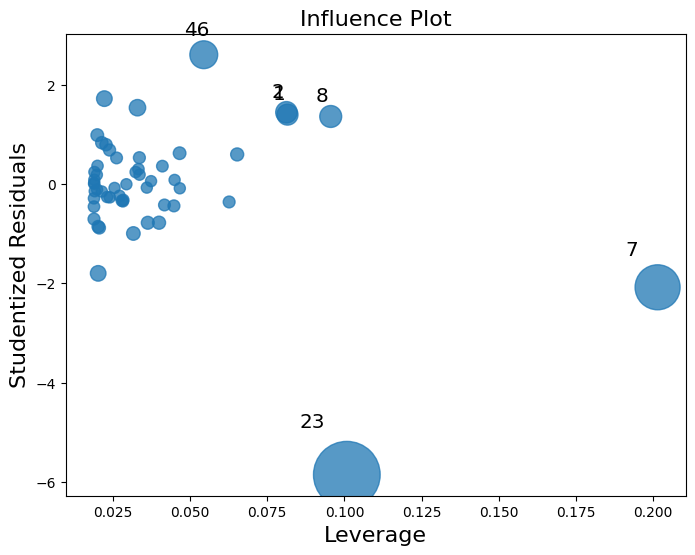

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
sm.graphics.influence_plot(results, ax=ax)
plt.show()

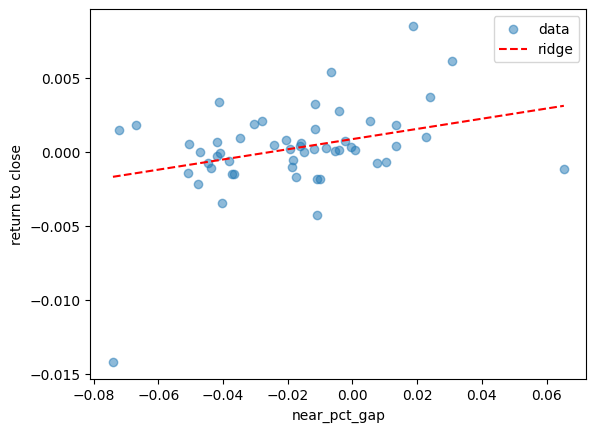

In [16]:
plt.scatter(X_train, y_train, color='tab:blue', alpha=0.5, label='data')
xline = np.linspace(np.min(X_train), np.max(X_train))
plt.plot(xline, xline * ridge.coef_[0] + ridge.intercept_[0], color='red', linestyle='--', linewidth=1.5, alpha=1, label='ridge')
plt.legend()
plt.xlabel("near_pct_gap")
plt.ylabel("return to close")
plt.show()
yhat = ridge.predict(X_test)

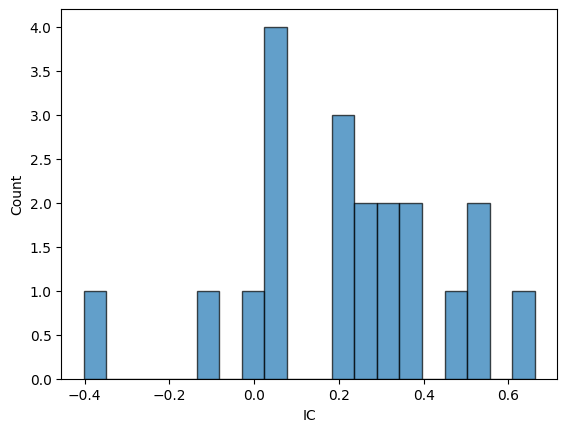

In [17]:
plt.hist(daily_ic["gap_ic"], edgecolor='black', alpha=0.7, bins=20)
plt.xlabel("IC")
plt.ylabel("Count")
plt.show()

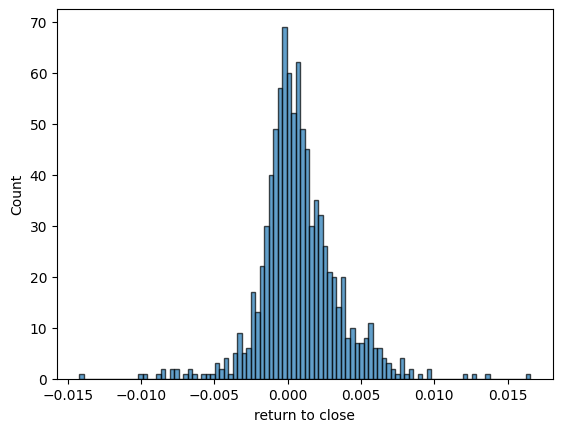

Jarque-Beta: stat=757.58, pval=0.00


In [18]:
plt.hist(plot_panel["ret"], edgecolor='black', alpha=0.7, bins=100)
plt.xlabel("return to close")
plt.ylabel("Count")
plt.show()

from scipy.stats import jarque_bera
stat, pval = jarque_bera(plot_panel['ret'])
print(f"Jarque-Beta: stat={stat:,.2f}, pval={pval:,.2f}")

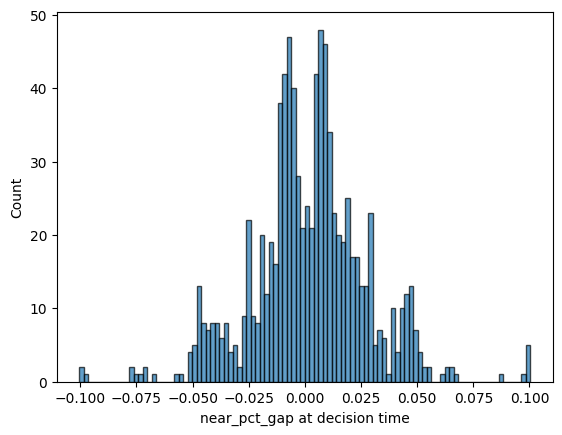

Jarque-Beta: stat=111.42, pval=0.00


In [19]:
plt.hist(plot_panel["near_pct_gap"], edgecolor='black', alpha=0.7, bins=100)
plt.xlabel("near_pct_gap at decision time")
plt.ylabel("Count")
plt.show()

from scipy.stats import jarque_bera
stat, pval = jarque_bera(plot_panel['near_pct_gap'])
print(f"Jarque-Beta: stat={stat:,.2f}, pval={pval:,.2f}")

#### Near Price + Paired QTY

In [20]:
plot_df = data.filter(
    pl.col('ts_event').dt.time().is_between(pl.time(15,55,00), pl.time(16,00,00)),
    pl.col('ts_event').dt.date() == pl.date(2026, 5, 22),
    pl.col('symbol') == "AMZN"
)
plot_df.head()

ts_event,symbol,ref_price,side,total_imbalance_qty,paired_qty,cont_book_clr_price,auct_interest_clr_price,qty_signal,session_dollar_volume,close,volume,near_pct_gap
"datetime[ns, America/New_York]",cat,f64,str,u32,u32,f64,f64,f64,f64,f64,u64,f64
2026-05-22 15:55:00 EDT,"""AMZN""",266.82,"""A""",348595,3298361,263.74,263.07,-0.083791,1.1098e9,266.76,6110,-0.011321
2026-05-22 15:55:01 EDT,"""AMZN""",266.76,"""A""",307351,3339605,264.18,263.58,-0.073891,1.1098e9,266.81,1471,-0.009857
2026-05-22 15:55:02 EDT,"""AMZN""",266.81,"""A""",308714,3338242,264.24,263.58,-0.074219,1.1098e9,266.81,1236,-0.009632
2026-05-22 15:55:03 EDT,"""AMZN""",266.81,"""A""",308714,3338242,264.23,263.58,-0.074227,1.1098e9,266.84,20,-0.009781
2026-05-22 15:55:04 EDT,"""AMZN""",266.83,"""A""",336620,3310336,264.24,263.58,-0.08094,1.1098e9,266.85,1441,-0.009781


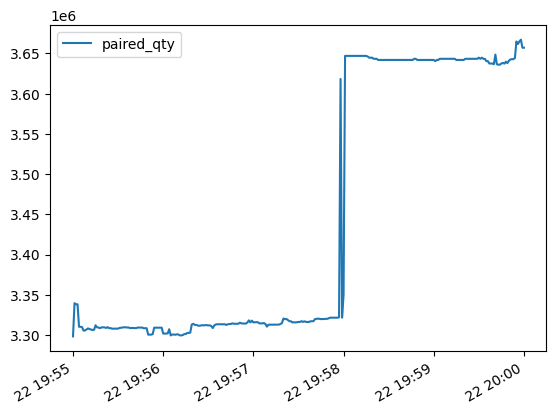

In [21]:
plt.plot(plot_df['ts_event'], plot_df['paired_qty'], label='paired_qty', color='tab:blue')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

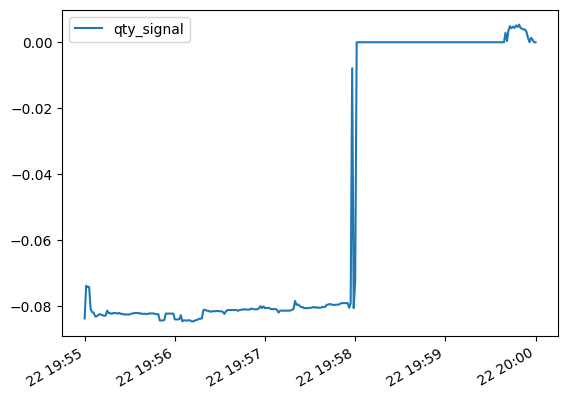

In [22]:
plt.plot(plot_df['ts_event'], plot_df['qty_signal'], label='qty_signal', color='tab:blue')
plt.legend()
plt.gcf().autofmt_xdate()

plt.show()

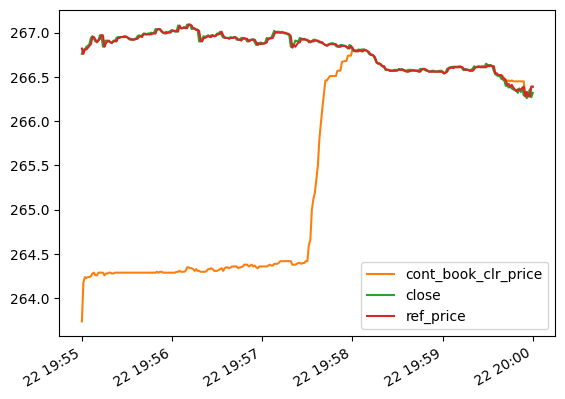

In [23]:
plt.plot(plot_df['ts_event'], plot_df['cont_book_clr_price'], label='cont_book_clr_price', color='tab:orange')
plt.plot(plot_df['ts_event'], plot_df['close'], label='close', color='tab:green')
plt.plot(plot_df['ts_event'], plot_df['ref_price'], label='ref_price', color='tab:red')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

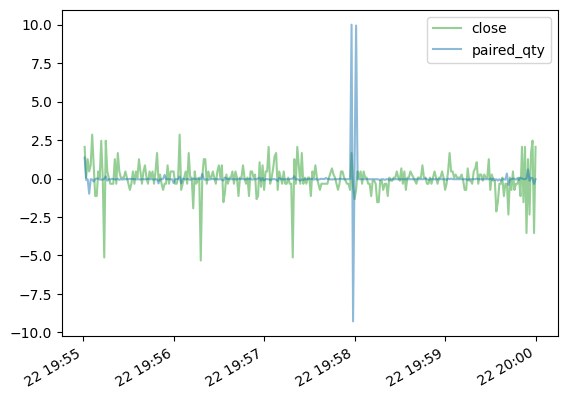

In [24]:
# plt.plot(plot_df['ts_event'], plot_df['cont_book_clr_price'].pct_change(), label='cont_book_clr_price', color='tab:orange')
plt.plot(plot_df['ts_event'], (plot_df['close'].pct_change() - plot_df['close'].pct_change().mean()) / plot_df['close'].pct_change().std(),
         label='close', color='tab:green', alpha=0.5)
# plt.plot(plot_df['ts_event'], plot_df['ref_price'].pct_change(), label='ref_price', color='tab:red')
plt.plot(plot_df['ts_event'], (plot_df['paired_qty'].pct_change() - plot_df['paired_qty'].pct_change().mean()) / plot_df['paired_qty'].pct_change().std(),
         label='paired_qty', color='tab:blue', alpha=0.5)
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

### Finding Each beta_i over rolling window
r_i ~ beta_i * r_mkt * w_i, find the beta_i

In [25]:
rets = data.group_by_dynamic(index_column='ts_event', group_by='symbol', every='1m').agg(pl.col('close').last()).with_columns(pl.col("close").pct_change().over("symbol").alias('return')).drop_nulls()

In [26]:
# Daily OLS beta to SPY using minute returns from the preceding 5 trading days
# (current day excluded). Vectorized polars: aggregate per (symbol, date) to
# sufficient stats, then rolling-sum across the prior 5 days.
#
# beta = Cov(r_i, r_spy) / Var(r_spy)
#      = (Σxy - Σx·Σy / n) / (Σy² - (Σy)² / n)        (the (n-1) cancels)

spy_rets = (
    rets.filter(pl.col("symbol") == "SPY")
        .select("ts_event", pl.col("return").alias("r_spy"))
)

daily_stats = (
    rets.join(spy_rets, on="ts_event", how="inner")
        .with_columns(pl.col("ts_event").dt.date().alias("date"))
        .group_by(["symbol", "date"])
        .agg(
            pl.len().alias("n"),
            pl.col("return").sum().alias("sx"),
            pl.col("r_spy").sum().alias("sy"),
            (pl.col("return") * pl.col("r_spy")).sum().alias("sxy"),
            (pl.col("r_spy") ** 2).sum().alias("sy2"),
        )
        .sort(["symbol", "date"])
)

w = 10
# shift(1) drops today out of the window; rolling_sum(5) sums the prior 5 days.
sum_cols = ["n", "sx", "sy", "sxy", "sy2"]
rolled = daily_stats.with_columns([
    pl.col(c).shift(1).rolling_sum(window_size=w).over("symbol").alias(f"{c}_{w}d")
    for c in sum_cols
])

betas = (
    rolled
    .with_columns(
        (
            (pl.col(f"sxy_{w}d") - pl.col(f"sx_{w}d") * pl.col(f"sy_{w}d") / pl.col(f"n_{w}d"))
            / (pl.col(f"sy2_{w}d") - pl.col(f"sy_{w}d") ** 2 / pl.col(f"n_{w}d"))
        ).alias("beta")
    )
    .filter(pl.col(f"n_{w}d") >= 30)
    .select(["date", "symbol", "beta"])
)

# Wide form: one row per date, one column per symbol.
betas_wide = betas.pivot(index="date", on="symbol", values="beta").sort("date")
betas_wide

date,A,AA,AAAU,AACG,AAL,AAMI,AAOI,AAON,AAOX,AAP,AAPB,AAPD,AAPL,AAPU,AAPX,AARD,AAT,AAUC,AAXJ,AB,ABAT,ABBV,ABCB,ABCL,ABEO,ABEV,ABG,ABM,ABNB,ABOS,ABR,ABSI,ABT,ABTC,ABTS,ABUS,…,ZAP,ZBAO,ZBH,ZBIO,ZBRA,ZCMD,ZD,ZENA,ZEO,ZEPP,ZETA,ZG,ZGN,ZH,ZIM,ZION,ZIP,ZKH,ZLAB,ZM,ZNTL,ZONE,ZOOZ,ZROZ,ZS,ZSL,ZSQR,ZTO,ZTR,ZTS,ZUMZ,ZURA,ZVIA,ZVRA,ZVZZT,ZWS,ZYME
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-05-11,1.215642,1.201732,0.417347,null,0.774826,-0.682473,1.692003,-0.7666,8.29791,0.658179,null,-0.894416,1.299259,2.469164,3.709812,2.587544,0.530979,0.870395,0.658149,0.314762,-0.056813,0.374692,0.417111,-3.468792,1.128259,0.106017,0.698201,-0.861769,0.409722,-2.439522,0.084492,-2.225005,0.116025,-0.376192,null,1.263271,…,null,null,-0.175232,0.672358,0.003869,null,0.095196,-0.618298,4.358798,-12.145709,1.608449,0.284363,1.091223,-0.011614,0.218153,0.736,2.433115,null,-0.052235,0.279852,-2.243236,null,-9.940106,0.168196,0.919542,-1.536942,-1.038171,0.263971,null,0.562604,-1.198804,-0.690665,3.666243,0.632831,null,-0.103359,0.476561
2026-05-12,1.009156,1.158088,0.432587,18.722939,1.076018,-0.591068,1.394195,-0.718534,7.793527,0.533064,3.740593,-0.845766,1.268714,2.42844,3.357135,1.517827,0.323104,1.249861,0.684802,-0.89294,-0.365689,0.458323,0.419823,-3.402594,1.176522,-0.069773,0.748687,-0.702332,0.407683,-1.916981,0.24797,-2.016738,0.074826,0.201195,null,1.461821,…,null,null,-0.108677,0.5693,0.219812,null,0.542559,-0.611978,4.434185,-10.673358,1.572473,0.463157,1.080531,0.246879,0.240624,0.682981,1.831031,0.859871,0.112345,0.450656,-1.916243,-20.420742,-10.319679,0.261154,0.859558,-1.600799,0.198043,0.293868,null,0.517729,-0.931097,-0.404903,3.431146,0.289297,null,-0.003692,0.6037
2026-05-13,0.981009,1.09724,0.193192,null,1.019119,-0.852453,1.876795,-0.129546,7.412327,0.585712,3.342578,-0.954608,1.282817,2.567114,-0.528358,1.434918,0.172569,1.200543,0.687015,-0.713361,-0.789471,0.313182,0.441427,-3.136402,0.949117,0.31026,0.799961,-0.556086,0.276563,-2.031472,0.071814,-1.935552,-0.015098,2.858691,-38.88434,1.056275,…,null,null,-0.238626,0.610436,0.071947,30.115699,0.646571,-0.524551,null,14.860709,1.632864,0.340532,0.995041,0.410254,0.184197,0.688898,2.227667,0.62294,0.079667,0.593426,-1.975692,-22.842979,-10.038302,0.304837,0.750098,-1.616379,1.54611,0.290259,null,0.425371,-1.080398,-0.55755,2.139455,0.269344,null,-0.069882,0.631583
2026-05-14,0.624036,1.109338,0.068054,null,0.853686,0.02208,2.604761,-0.141028,8.562662,0.450504,3.639857,-1.009217,1.233344,2.570795,-5.102467,2.009982,0.141899,1.06231,-0.556846,-1.992162,-0.914195,0.368957,0.88301,-3.635275,0.800425,0.38932,1.077767,-0.585312,-0.071801,-0.127475,0.486942,0.094745,0.221332,3.734376,-39.087851,0.062975,…,null,null,0.263124,-0.478328,0.135795,null,0.869135,-1.603326,null,9.151399,1.560281,0.420156,1.686031,2.82337,-0.354363,0.84054,1.292993,0.427972,-0.090941,0.711718,-0.735148,-14.401522,-19.901787,0.748911,0.925142,-1.445551,2.800326,-0.046782,null,0.488402,-2.517942,0.081276,4.098843,0.240678,null,0.395958,0.582806
2026-05-15,0.496751,0.800343,0.056102,null,0.781173,0.46608,3.849213,0.167104,10.782254,0.294473,2.430382,-0.545096,1.010557,2.192205,null,0.914942,0.023453,0.924728,-1.022757,-1.586031,-0.483762,0.260483,0.84505,-0.853242,1.277864,0.408379,1.184065,0.88574,-0.174411,1.040637,0.014268,-1.580902,0.183159,2.777843,null,-0.955472,…,null,null,0.29953,-0.619343,0.450445,29.337521,0.675842,-2.755838,12.63229,11.154543,1.696649,0.290832,1.319432,3.380574,0.014178,0.720287,1.357137,-0.726405,-0.221756,0.843185,0.163906,-19.967267,-8.125553,0.606157,1.06118,-1.441337,4.481011,0.086585,null,0.230001,-2.494423,-0.021278,3.119009,-0.461692,null,1.010342,0.875915
2026-05-18,0.5413,1.061507,-0.022001,null,1.034856,0.726389,2.694354,-

### Alpha Forecasting

In [27]:
# Training panel: one row per (date, symbol, snap_time) for every 30s snap in
# 15:50-16:00. At each snap we ASOF-join the latest row at-or-before the snap
# for that (date, symbol), so we don't silently drop symbols that lack a row
# exactly on the snap second. Each snap_time learns its own (signal -> ret)
# horizon (built-in time decay -- 16:00 has zero horizon so its beta collapses
# to 0 naturally).

close_eod = (
    data
    .group_by_dynamic(index_column="ts_event", group_by="symbol", every="1d")
    .agg(pl.col("close").last().alias("close_eod"))
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .select(["date", "symbol", "close_eod"])
)

# Build (date, symbol, snap_ts) grid: 21 snap times per (date, symbol)
# snap_ts = midnight(NY) + 57000s (=15:50:00) + snap_offset_s
day_symbols = (
    data
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .select("date", "symbol")
    .unique()
)
snap_offsets = pl.DataFrame(
    {"snap_offset_s": list(range(0, 601, 30))},
    schema={"snap_offset_s": pl.Int64},
)
grid = (
    day_symbols.join(snap_offsets, how="cross")
    .with_columns(
        snap_ts=pl.col("date") + pl.duration(seconds=57_000 + pl.col("snap_offset_s")),
    )
    .with_columns(pl.col("snap_ts").dt.time().alias("snap_time"))
    .sort(["date", "symbol", "snap_ts"])
)

# ASOF-join: take the most recent row at-or-before snap_ts within (date, symbol).
# Scoping by date prevents the "backward" search from reaching yesterday's 16:00.
data_with_date = (
    data
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"),
                  pl.col('ts_event').dt.cast_time_unit('us').alias('ts_event'))
    .sort(["date", "symbol", "ts_event"])
)

snaps = (
    grid.join_asof(
        data_with_date,
        left_on="snap_ts",
        right_on="ts_event",
        by=["date", "symbol"],
        strategy="backward",
    )
    .select([
        "date", "snap_time", "symbol", "side",
        pl.col("close").alias("close_snap"),
        "qty_signal", "near_pct_gap", "session_dollar_volume",
    ])
    .sort(['date', 'snap_time'])
)

interval_panel = (
    snaps.join(close_eod, on=["date", "symbol"], how="inner")
    .with_columns(
        ((pl.col("close_eod") - pl.col("close_snap")) / pl.col("close_snap")).alias("ret")  # return-to-close horizon
    )
    .drop_nulls(["ret", "qty_signal", "near_pct_gap"])
    .with_columns(
        pl.col("session_dollar_volume").rank(method="min").over(["date", "snap_time"]).alias("_rk"),
        pl.len().over(["date", "snap_time"]).alias("_n"),
    )
    .filter(pl.col("_rk") / pl.col("_n") >= 0.80)   # top 10% by ADV each day
    .drop(["_rk", "_n"])
    .filter(
        pl.col("side") != "N",
        pl.col("qty_signal").abs() > 0.01,
        pl.col("near_pct_gap").abs() != 1.0,
    )
    .sort(["date", "snap_time", "symbol"])
)

print(f"Panel rows: {len(interval_panel):,}")
print(f"Snap times: {interval_panel['snap_time'].n_unique()}  |  Dates: {interval_panel['date'].n_unique()}")
interval_panel.head()

/var/folders/72/cq20lp7n6zngdk68w66r9q9r0000gn/T/ipykernel_6422/3501858148.py:47: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  grid.join_asof(


Panel rows: 78,168
Snap times: 11  |  Dates: 20


date,snap_time,symbol,side,close_snap,qty_signal,near_pct_gap,session_dollar_volume,close_eod,ret
"datetime[ns, America/New_York]",time,cat,str,f64,f64,f64,f64,f64,f64
2026-04-27 00:00:00 EDT,15:55:00,"""AAOI""","""A""",145.535,-0.040093,-0.017418,2.6834e8,145.78,0.001683
2026-04-27 00:00:00 EDT,15:55:00,"""AAON""","""A""",91.83,-0.108282,-0.04737,1.7739e7,91.64,-0.002069
2026-04-27 00:00:00 EDT,15:55:00,"""AAPL""","""A""",267.5,-0.029235,-0.001869,1.4971e9,267.61,0.000411
2026-04-27 00:00:00 EDT,15:55:00,"""ABVX""","""A""",112.39,-0.02276,-0.011478,1.4063e7,111.9,-0.00436
2026-04-27 00:00:00 EDT,15:55:00,"""ACGL""","""A""",96.45,-0.303145,-0.049145,2.5447e7,96.35,-0.001037


In [28]:
# Step 1: Cross-sectional rolling OLS of ret ~ near_pct_gap per snap_time, fit on
# the prior 3 days at THAT SAME snap_time (exclusive of day t). The rolling sum
# is computed within each snap_time so the fit at (snap_time=s, date=t) uses
# only (s, {t-3, t-2, t-1}) -- no look-ahead, and each snap_time gets its own
# beta capturing its specific (signal -> ret) horizon.
#
# beta_near = (Sxy - Sx*Sy/n) / (Sx2 - Sx^2/n)
# beta_0    = ybar - beta_near * xbar

daily_xy = (
    interval_panel
    .group_by(["snap_time", "date"])
    .agg(
        pl.len().alias("n"),
        pl.col("near_pct_gap").sum().alias("sx"),
        pl.col("ret").sum().alias("sy"),
        (pl.col("near_pct_gap") * pl.col("ret")).sum().alias("sxy"),
        (pl.col("near_pct_gap") ** 2).sum().alias("sx2"),
    )
    .sort(["snap_time", "date"])
)

W = 7
rolling_betas = (
    daily_xy
    .with_columns([
        pl.col(c).shift(1).rolling_sum(window_size=W).over("snap_time").alias(f"{c}_w")
        for c in ["n", "sx", "sy", "sxy", "sx2"]
    ])
    .with_columns(
        beta_near=(
            (pl.col("sxy_w") - pl.col("sx_w") * pl.col("sy_w") / pl.col("n_w"))
            / (pl.col("sx2_w") - pl.col("sx_w") ** 2 / pl.col("n_w"))
        ),
    )
    .with_columns(
        beta_0=pl.col("sy_w") / pl.col("n_w")
                - pl.col("beta_near") * pl.col("sx_w") / pl.col("n_w"),
    )
    .select(["snap_time", "date", "n_w", "beta_near", "beta_0"])
    .drop_nulls()
    .rename({"n_w": "n_train"})
    .sort(["date", "snap_time"])
)
rolling_betas

snap_time,date,n_train,beta_near,beta_0
time,"datetime[ns, America/New_York]",u32,f64,f64
15:55:00,2026-05-06 00:00:00 EDT,2228,0.017304,0.000541
15:55:30,2026-05-06 00:00:00 EDT,2551,0.019005,0.000455
15:56:00,2026-05-06 00:00:00 EDT,2661,0.015142,0.000418
15:56:30,2026-05-06 00:00:00 EDT,2750,0.015912,0.000376
15:57:00,2026-05-06 00:00:00 EDT,2840,0.018267,0.00032
…,…,…,…,…
15:58:00,2026-05-22 00:00:00 EDT,2544,0.113128,0.00004
15:58:30,2026-05-22 00:00:00 EDT,2508,0.164383,0.000038
15:59:00,2026-05-22 00:00:00 EDT,2520,0.18358,-0.000023


In [29]:
# Step 2: Forecast alpha_{i, t, s} = beta_0_{s,t} + beta_near_{s,t} * near_pct_gap_{i,t,s}
# for every (symbol, 30s snap) in 15:50-16:00. Same ASOF-join pattern as the
# panel cell -- the snap grid drives the asof, and the (snap_time, date)-specific
# rolling fit is joined in. Time decay is baked in: by 16:00 the horizon is zero
# and beta collapses to ~0 naturally.
#
# Invalid signal rows (side=='N', null near_pct_gap, |near_pct_gap| == 1.0)
# get alpha = null -- fill to 0.0 downstream when building the backtest tensor.

day_symbols = (
    data
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .select("date", "symbol")
    .unique()
)
snap_offsets = pl.DataFrame(
    {"snap_offset_s": list(range(0, 601, 30))},
    schema={"snap_offset_s": pl.Int64},
)
grid = (
    day_symbols.join(snap_offsets, how="cross")
    .with_columns(
        snap_ts=pl.col("date") + pl.duration(seconds=57_000 + pl.col("snap_offset_s")),
    )
    .with_columns(pl.col("snap_ts").dt.time().alias("snap_time"))
    .sort(["date", "symbol", "snap_ts"])
)

data_with_date = (
    data
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"),
                  pl.col('ts_event').dt.cast_time_unit('us').alias('ts_event'))
    .sort(["date", "symbol", "ts_event"])
)

forecast_grid = (
    grid.join_asof(
        data_with_date,
        left_on="snap_ts",
        right_on="ts_event",
        by=["date", "symbol"],
        strategy="backward",
    )
    .select([
        pl.col("snap_ts").alias("ts_event"),
        "date", "snap_time", "symbol", "side", "close", "near_pct_gap",
    ])
    .sort(['date', 'snap_time'])
)

alpha_forecast = (
    forecast_grid
    .join(
        rolling_betas.select("snap_time", "date", "beta_near", "beta_0"),
        on=["snap_time", "date"], how="left",
    )
    .with_columns(
        pl.when(
            pl.col("side") != "N",
            pl.col("near_pct_gap").is_not_null(),
            pl.col("near_pct_gap").abs() != 1.0,
            pl.col("beta_near").is_not_null(),
        )
        .then(pl.col("beta_0") + pl.col("beta_near") * pl.col("near_pct_gap"))
        .otherwise(None)
        .alias("alpha")
    )
    .select([
        "ts_event", "symbol", "snap_time", "near_pct_gap", "side", "close",
        "beta_near", "beta_0", "alpha",
    ])
    .sort(["ts_event", "symbol"])
)

print(f"Forecast rows: {len(alpha_forecast):,}")
print(f"Non-null alphas: {alpha_forecast['alpha'].is_not_null().sum():,}")
print(f"Unique snapshots: {alpha_forecast['ts_event'].n_unique()}  |  symbols: {alpha_forecast['symbol'].n_unique():,}")
alpha_forecast.filter(pl.col("alpha").is_not_null()).head(10)

/var/folders/72/cq20lp7n6zngdk68w66r9q9r0000gn/T/ipykernel_6422/3229566773.py:37: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  grid.join_asof(


Forecast rows: 3,605,784
Non-null alphas: 228,234
Unique snapshots: 420  |  symbols: 11,582


ts_event,symbol,snap_time,near_pct_gap,side,close,beta_near,beta_0,alpha
"datetime[μs, America/New_York]",cat,time,f64,str,f64,f64,f64,f64
2026-05-06 15:55:00 EDT,"""AAL""",15:55:00,-0.005812,"""A""",12.905,0.017304,0.000541,0.000441
2026-05-06 15:55:00 EDT,"""AAOI""",15:55:00,-0.009079,"""A""",178.44,0.017304,0.000541,0.000384
2026-05-06 15:55:00 EDT,"""AAON""",15:55:00,-0.099554,"""A""",98.64,0.017304,0.000541,-0.001181
2026-05-06 15:55:00 EDT,"""AAPL""",15:55:00,0.008481,"""B""",287.69,0.017304,0.000541,0.000688
2026-05-06 15:55:00 EDT,"""AAPU""",15:55:00,-0.000845,"""A""",35.51,0.017304,0.000541,0.000527
2026-05-06 15:55:00 EDT,"""ABCL""",15:55:00,0.013092,"""B""",4.965,0.017304,0.000541,0.000768
2026-05-06 15:55:00 EDT,"""ABNB""",15:55:00,0.010935,"""B""",139.92,0.017304,0.000541,0.000731
2026-05-06 15:55:00 EDT,"""ABUS""",15:55:00,0.00565,"""B""",4.425,0.017304,0.000541,0.000639
2026-05-06 15:55:00 EDT,"""ABVX""",15:55:00,0.002589,"""B""",127.47,0.017304,0.000541,0.000586


In [30]:
# Linear decay schedule: convert close-horizon alpha into per-step expected
# return mu_step. At snap k there are (NUM_INTERVALS - k) 30s steps remaining
# to close; distribute the close-horizon alpha evenly over them:
#
#     mu_step_{i, s_k} = alpha_{i, s_k} / (NUM_INTERVALS - k)
#
# This is the per-step expected return the MPO controller will assume for the
# current step at decision time s_k. Last snap (16:00) has 0 remaining steps
# and gets mu_step = null.

NUM_INTERVALS = 20  # 30s intervals from 15:50:00 to 16:00:00

alpha_forecast = (
    alpha_forecast
    .with_columns(
        snap_idx=(
            (
                pl.col("snap_time").dt.hour() * 3600
                + pl.col("snap_time").dt.minute() * 60
                + pl.col("snap_time").dt.second()
                - 57_000
            ) // 30
        ).cast(pl.Int64),
    )
    .with_columns(
        n_remaining=(NUM_INTERVALS - pl.col("snap_idx")).cast(pl.Int64),
    )
    .with_columns(
        mu_step=pl.when(pl.col("n_remaining") > 0)
                  .then(pl.col("alpha") / pl.col("n_remaining"))
                  .otherwise(None),
    )
    .sort(["ts_event", "symbol"])
)

print(f"Rows: {len(alpha_forecast):,}")
print(f"Non-null mu_step: {alpha_forecast['mu_step'].is_not_null().sum():,}")
alpha_forecast.filter(pl.col("mu_step").is_not_null()).head(10)

Rows: 3,605,784
Non-null mu_step: 228,234


ts_event,symbol,snap_time,near_pct_gap,side,close,beta_near,beta_0,alpha,snap_idx,n_remaining,mu_step
"datetime[μs, America/New_York]",cat,time,f64,str,f64,f64,f64,f64,i64,i64,f64
2026-05-06 15:55:00 EDT,"""AAL""",15:55:00,-0.005812,"""A""",12.905,0.017304,0.000541,0.000441,-2286,2306,1.9120e-7
2026-05-06 15:55:00 EDT,"""AAOI""",15:55:00,-0.009079,"""A""",178.44,0.017304,0.000541,0.000384,-2286,2306,1.6668e-7
2026-05-06 15:55:00 EDT,"""AAON""",15:55:00,-0.099554,"""A""",98.64,0.017304,0.000541,-0.001181,-2286,2306,-5.1222e-7
2026-05-06 15:55:00 EDT,"""AAPL""",15:55:00,0.008481,"""B""",287.69,0.017304,0.000541,0.000688,-2286,2306,2.9845e-7
2026-05-06 15:55:00 EDT,"""AAPU""",15:55:00,-0.000845,"""A""",35.51,0.017304,0.000541,0.000527,-2286,2306,2.2847e-7
2026-05-06 15:55:00 EDT,"""ABCL""",15:55:00,0.013092,"""B""",4.965,0.017304,0.000541,0.000768,-2286,2306,3.3304e-7
2026-05-06 15:55:00 EDT,"""ABNB""",15:55:00,0.010935,"""B""",139.92,0.017304,0.000541,0.000731,-2286,2306,3.1686e-7
2026-05-06 15:55:00 EDT,"""ABUS""",15:55:00,0.00565,"""B""",4.425,0.017304,0.000541,0.000639,-2286,2306,2.7720e-7
2026-05-06 15:55:00 EDT,"""ABVX""",15:55:00,0.002589,"""B""",127.47,0.017304,0.000541,0.000586,-2286,2306,2.5423e-7


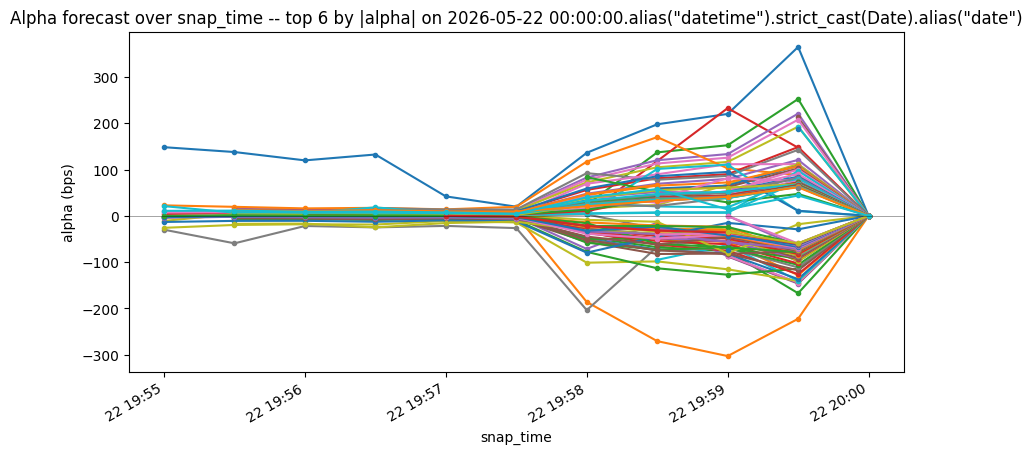

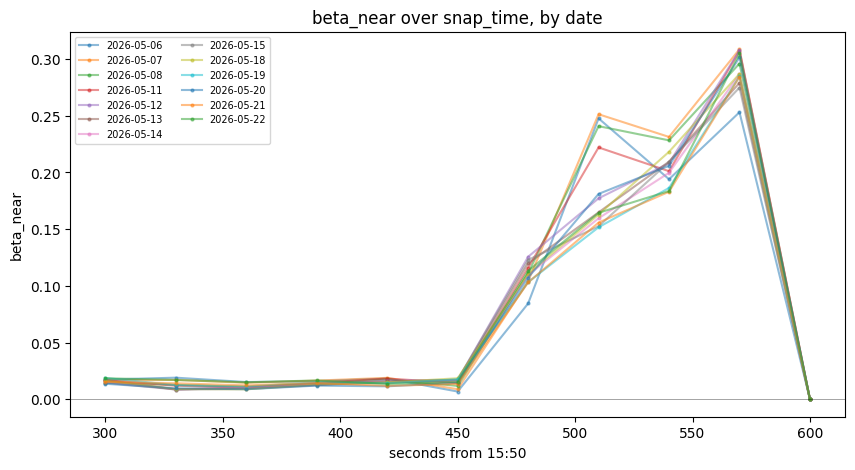

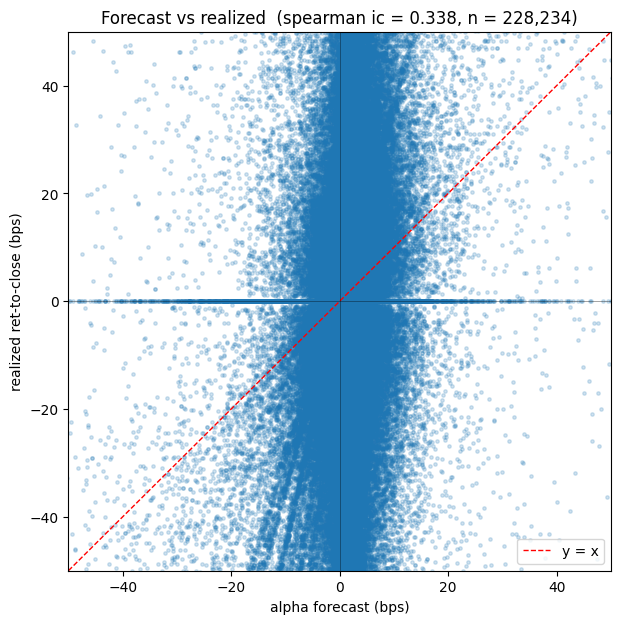

Mean per-bin Spearman IC: 0.387
Median: 0.346
% bins with IC > 0: 100.0%


In [31]:
# Visualize the alpha forecasts: (1) alpha time-series per symbol on one date,
# (2) beta_near over snap_time across dates, (3) forecast vs realized scatter.
import matplotlib.pyplot as plt

VIZ_DATE = pl.date(2026, 5, 22)


# ---------------------------------------------------------------------------
# (1) alpha forecast vs snap_time for the most active symbols on VIZ_DATE
# ---------------------------------------------------------------------------
# .filter(pl.col("ts_event").dt.date() == VIZ_DATE, pl.col("alpha").is_not_null())
day = (
    alpha_forecast
    .filter(pl.col("ts_event").dt.date() == VIZ_DATE, pl.col("alpha").is_not_null())
)
top_syms = (
    day.group_by("symbol")
       .agg(pl.col("alpha").abs().max().alias("max_abs"))
       .sort("max_abs", descending=True)
       .head(100)["symbol"].to_list()
)

fig, ax = plt.subplots(figsize=(10, 5))
for sym in top_syms:
    sub = day.filter(pl.col("symbol") == sym).sort("ts_event")
    ax.plot(sub["ts_event"], sub["alpha"] * 1e4, marker="o", markersize=3, label=sym)
ax.axhline(0, color="black", linewidth=0.5, alpha=0.5)
ax.set_title(f"Alpha forecast over snap_time -- top 6 by |alpha| on {VIZ_DATE}")
ax.set_xlabel("snap_time")
ax.set_ylabel("alpha (bps)")
# ax.legend(loc="best", fontsize=8)
fig.autofmt_xdate()
plt.show()


# ---------------------------------------------------------------------------
# (2) beta_near over snap_time, one line per date
# ---------------------------------------------------------------------------
def secs_from_1550(t):
    return (t.hour - 15) * 3600 + (t.minute - 50) * 60 + t.second

dates = rolling_betas["date"].unique().sort().to_list()
fig, ax = plt.subplots(figsize=(10, 5))
for d in dates:
    g = rolling_betas.filter(pl.col("date") == d).sort("snap_time")
    xs = [secs_from_1550(t) for t in g["snap_time"].to_list()]
    ax.plot(xs, g["beta_near"], alpha=0.5, marker="o", markersize=2,
            label=d.strftime("%Y-%m-%d"))
ax.axhline(0, color="black", linewidth=0.5, alpha=0.5)
ax.set_title("beta_near over snap_time, by date")
ax.set_xlabel("seconds from 15:50")
ax.set_ylabel("beta_near")
ax.legend(loc="best", fontsize=7, ncol=2)
plt.show()


# ---------------------------------------------------------------------------
# (3) Forecast vs realized ret-to-close (in bps)
# ---------------------------------------------------------------------------
eod = (
    data
    .group_by_dynamic(index_column="ts_event", group_by="symbol", every="1d")
    .agg(pl.col("close").last().alias("close_eod"))
    .with_columns(pl.col("ts_event").dt.truncate("1d").dt.cast_time_unit("us").alias("date"))
    .select("date", "symbol", "close_eod")
)

scatter = (
    alpha_forecast
    .filter(pl.col("alpha").is_not_null())
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .join(eod, on=["date", "symbol"], how="inner")
    .with_columns(((pl.col("close_eod") - pl.col("close")) / pl.col("close")).alias("ret_realized"))
)


ic = scatter.select(pl.corr(pl.col("alpha").rank(), pl.col("ret_realized").rank())).item()
a_bps = scatter["alpha"].to_numpy() * 1e4
r_bps = scatter["ret_realized"].to_numpy() * 1e4
# lim = max(abs(a_bps).max(), abs(r_bps).max()) * 0.10
lim = 50

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(a_bps, r_bps, alpha=0.2, s=6)
ax.plot([-lim, lim], [-lim, lim], color="red", linestyle="--", linewidth=1, label="y = x")
ax.axhline(0, color="black", linewidth=0.5, alpha=0.5)
ax.axvline(0, color="black", linewidth=0.5, alpha=0.5)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("alpha forecast (bps)")
ax.set_ylabel("realized ret-to-close (bps)")
ax.set_title(f"Forecast vs realized  (spearman ic = {ic:.3f}, n = {len(scatter):,})")
ax.legend()
plt.show()

ic_per_bin = (
      scatter
      .filter(pl.col('snap_time').dt.time() != pl.time(16,00,00),)
      .group_by(["date", "snap_time"])
      .agg(
          pl.corr(pl.col("alpha").rank(), pl.col("ret_realized").rank()).alias("ic"),
          pl.len().alias("n"),
      )
      .filter(pl.col("n") >= 10)   # need a few names for rank corr to be meaningful
  )
print(f"Mean per-bin Spearman IC: {ic_per_bin['ic'].mean():.3f}")
print(f"Median: {ic_per_bin['ic'].median():.3f}")
print(f"% bins with IC > 0: {(ic_per_bin['ic'] > 0).mean():.1%}")

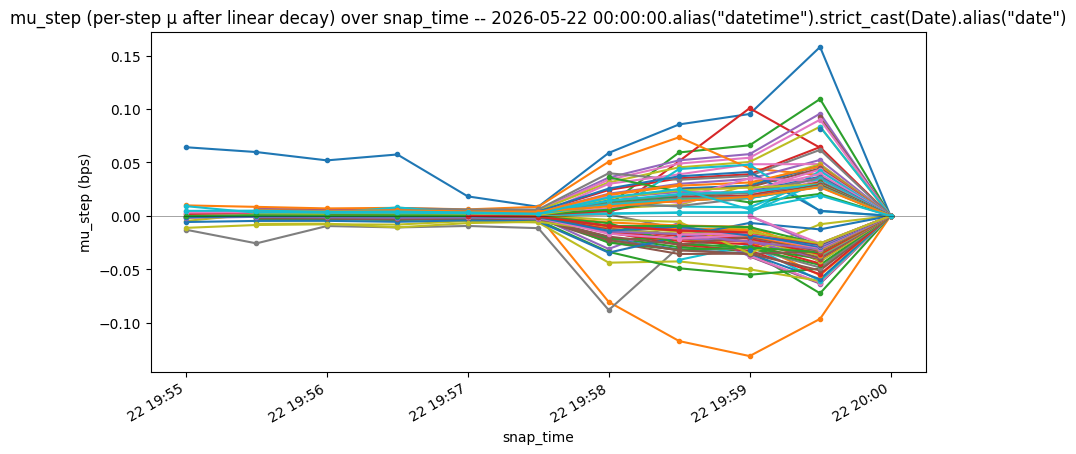

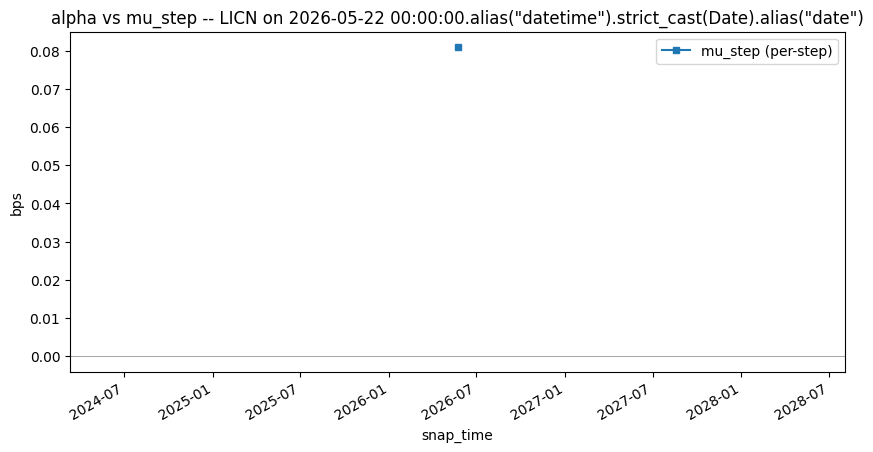

In [34]:
# mu_step time-series: per-step expected return after linear decay.
# Compared to alpha, magnitudes grow toward 16:00 because n_remaining shrinks
# (the close-horizon alpha gets divided over fewer remaining steps).

day_mu = (
    alpha_forecast
    .filter(pl.col("ts_event").dt.date() == VIZ_DATE, pl.col("mu_step").is_not_null())
)
top_syms_mu = (
    day_mu.group_by("symbol")
          .agg(pl.col("mu_step").abs().max().alias("max_abs"))
          .sort("max_abs", descending=True)
          .head(100)["symbol"].to_list()
)

fig, ax = plt.subplots(figsize=(10, 5))
for sym in top_syms_mu:
    sub = day_mu.filter(pl.col("symbol") == sym).sort("ts_event")
    ax.plot(sub["ts_event"], sub["mu_step"] * 1e4, marker="o", markersize=3, label=sym)
ax.axhline(0, color="black", linewidth=0.5, alpha=0.5)
ax.set_title(f"mu_step (per-step μ after linear decay) over snap_time -- {VIZ_DATE}")
ax.set_xlabel("snap_time")
ax.set_ylabel("mu_step (bps)")
fig.autofmt_xdate()
plt.show()


# Side-by-side: alpha (close-horizon) vs mu_step for a single representative symbol.
# Highlights how the same close-horizon forecast gets distributed into per-step μ
# that monotonically grows in magnitude as fewer steps remain.

if top_syms_mu:
    sym = top_syms_mu[10]
    sub = (
        alpha_forecast
        .filter(pl.col("ts_event").dt.date() == VIZ_DATE,
                pl.col("symbol") == sym,
                pl.col("alpha").is_not_null())
        .sort("ts_event")
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    # ax.plot(sub["ts_event"], sub["alpha"] * 1e4, marker="o", markersize=4, label="alpha (close-horizon)")
    ax.plot(sub["ts_event"], sub["mu_step"] * 1e4, marker="s", markersize=4, label="mu_step (per-step)")
    ax.axhline(0, color="black", linewidth=0.5, alpha=0.5)
    ax.set_title(f"alpha vs mu_step -- {sym} on {VIZ_DATE}")
    ax.set_xlabel("snap_time")
    ax.set_ylabel("bps")
    ax.legend()
    fig.autofmt_xdate()
    plt.show()

In [35]:
alpha_forecast

ts_event,symbol,snap_time,near_pct_gap,side,close,beta_near,beta_0,alpha,snap_idx,n_remaining,mu_step
"datetime[μs, America/New_York]",cat,time,f64,str,f64,f64,f64,f64,i64,i64,f64
2026-04-27 15:50:00 EDT,"""A""",15:50:00,-1.0,"""N""",115.71,null,null,null,-2287,2307,null
2026-04-27 15:50:00 EDT,"""AA""",15:50:00,-1.0,"""N""",67.43,null,null,null,-2287,2307,null
2026-04-27 15:50:00 EDT,"""AAAU""",15:50:00,null,null,null,null,null,null,-2287,2307,null
2026-04-27 15:50:00 EDT,"""AACB""",15:50:00,null,null,null,null,null,null,-2287,2307,null
2026-04-27 15:50:00 EDT,"""AACG""",15:50:00,null,null,null,null,null,null,-2287,2307,null
…,…,…,…,…,…,…,…,…,…,…,…
2026-05-22 16:00:00 EDT,"""ZVRA""",16:00:00,0.0,"""N""",10.03,0.0,0.0,null,-2165,2185,null
2026-05-22 16:00:00 EDT,"""ZVZZT""",16:00:00,null,null,18.49,0.0,0.0,null,-2165,2185,null
2026-05-22 16:00:00 EDT,"""ZWS""",16:00:00,-1.0,"""N""",48.01,0.0,0.0,null,-2165,2185,null
